In [3]:
!pip install -q git+https://github.com/facebookresearch/segment-anything.git


[notice] A new release of pip is available: 24.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [1]:
import torch
import cv2
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
import time

In [7]:
# smallest model for now # this can and probably should change
checkpoint_path = "sam_vit_b_01ec64.pth" # for right now I am adding a file I have downloaded on my machine and gitignoring it # Found in ReadMe of: https://github.com/facebookresearch/segment-anything
model_type = "vit_b"

In [8]:
import torchvision
from segment_anything import sam_model_registry, SamPredictor

In [9]:
device = "cuda" if torch.cuda.is_available() else "cpu"

sam = sam_model_registry[model_type](checkpoint=checkpoint_path) # load model
sam.to(device=device) # gpu or cpu
predictor = SamPredictor(sam)

In [10]:
import pandas as pd

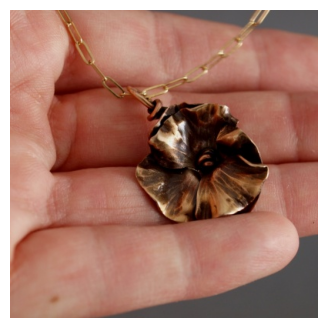

In [118]:
devDF = pd.read_csv('dev_split.csv')
devArr = devDF.to_numpy()

testDF = pd.read_csv('test_split.csv')
testArr = testDF.to_numpy()

image = cv2.imread(str(f"data/images/{str(testArr[0][0])}"))
image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(10, 4))

plt.imshow(image)
plt.axis("off")

plt.show()

In [119]:
predictor.set_image(image)

h, w = image.shape[:2]

input_point = np.array([[h//2, w//2]])
input_label = np.array([1])

masks, scores, logits = predictor.predict(
    point_coords=input_point,
    point_labels=input_label,
    multimask_output=True
)
print(scores)

[0.89302254 0.8188146  0.6883514 ]


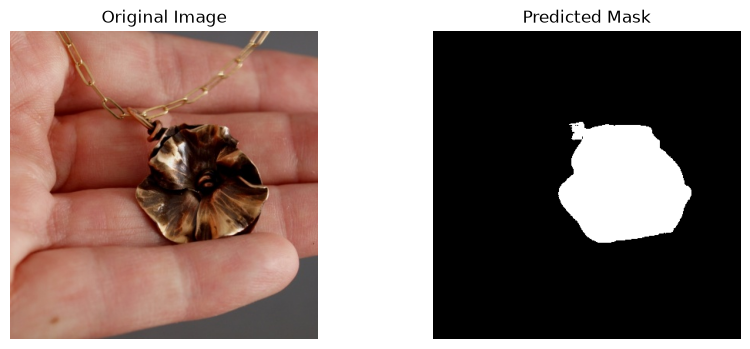

In [120]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

axes[0].imshow(image)
axes[0].set_title("Original Image")

axes[1].imshow(masks[0], cmap="gray")
axes[1].set_title("Predicted Mask")

for ax in axes:
    ax.axis("off")

plt.show()

In [78]:
def show_masks(image, masks):
    fig, ax = plt.subplots(figsize=(10, 10))

    # Show original image
    ax.imshow(image)

    #colorsCount = len(masks)
    #print(colorsCount)
    # Colors for the masks
    colors = [
        [1, 0, 0],   # red
        [0, 1, 0],   # green
        [0, 0, 1],   # blue
        [1, 1, 0],   # yellow
        [1, 0, 1],   # magenta
        [0, 1, 1]    # cyan
    ]
    
    #for i in range(colorsCount):
    #    #colors.append([i%2*i, i%3*i, i%5*i])
    #    colors.append([int(i%2*i+100), int(i%3*i+100), int(i%5*i+100)])

    for i, mask in enumerate(masks):
        color = colors[i % len(colors)]

        # Create an RGB image of the mask's color
        #colored_mask = np.zeros((400, 400, 3)) # (*mask.shape, 3)
        #colored_mask[:, :, :] = color
        colored_mask = np.zeros((*mask.shape, 4))
        colored_mask[:, :, :3] = color
        colored_mask[:, :, 3] = mask * 0.4

        ax.imshow(colored_mask)

    ax.axis("off")
    plt.show()

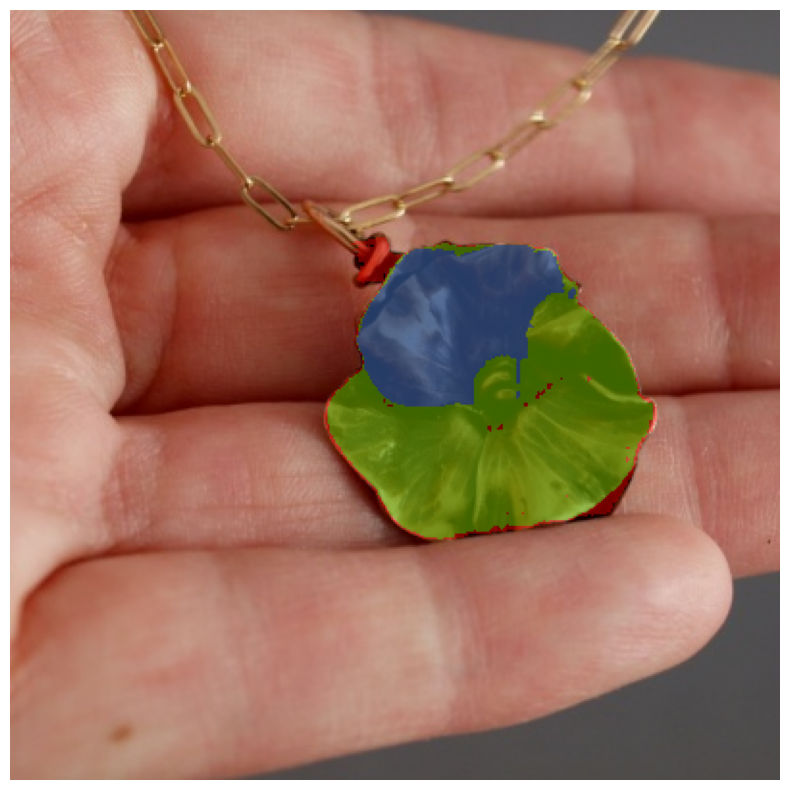

In [121]:
show_masks(image, masks)

In [81]:
from segment_anything import SamAutomaticMaskGenerator

In [ ]:
# This has a different format with each mask being a dictionary # it also detects everything in the image which takes way longer
mask_generator = SamAutomaticMaskGenerator(sam)
masks = mask_generator.generate(image)

In [126]:
from tqdm import tqdm

In [138]:
# for all images in testArr, load, run predictor, save masks[0]

masksArr = []

for i in tqdm(range(len(testArr)), "SAM Mask Generation"):
    image = cv2.imread(str(f"data/images/{str(testArr[i][0])}"))
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    predictor.set_image(image)

    h, w = image.shape[:2]

    input_point = np.array([[w//2, h//2]])
    input_label = np.array([1])

    masks, scores, logits = predictor.predict(
        point_coords=input_point,
        point_labels=input_label,
        multimask_output=True
        )
    #print(scores)

    masksArr.append(masks[0])



SAM Mask Generation:   0%|          | 0/300 [00:00<?, ?it/s]

SAM Mask Generation: 100%|██████████| 300/300 [18:44<00:00,  3.75s/it]


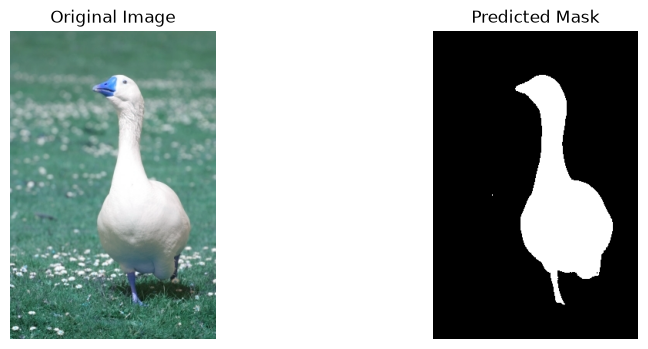

In [147]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

axes[0].imshow(cv2.imread(str(f"data/images/{str(testArr[5][0])}")))
axes[0].set_title("Original Image")

axes[1].imshow(masksArr[5], cmap="gray")
axes[1].set_title("Predicted Mask")

for ax in axes:
    ax.axis("off")

plt.show()

In [148]:
outputPath = Path("outputs/SAM_lightweight_proper")
outputPath.mkdir(parents=True, exist_ok=True)

for i in range(len(masksArr)):
    mask = (masksArr[i] * 255).astype(np.uint8)
    cv2.imwrite(f"{outputPath}/{testArr[i][0]}", mask)